# Coastal Ridge Segmentation Using GeoAI Python Package

This notebook is based on the template provided by GeoAI "Train a Semantic Segmentation Model using Segmentation-Models-PyTorch"

[![image](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/opengeos/geoai/blob/main/docs/examples/train_segmentation_model.ipynb)

It demonstrates how to train a semantic segmentation model for coastal ridge segmentation using the [segmentation-models-pytorch](https://smp.readthedocs.io) library. This approach treats the task as pixel-level binary classification.

## Install packages



In [ ]:
pip install geoai-py==0.28.0 # Installation of GeoAI python package 0.28.0

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 739.5/739.5 kB 22.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.9/24.9 MB 127.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 55.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 105.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 52.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 73.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.7/33.7 MB 41.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 45.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 76.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 593.1/593.1 kB 20.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 47.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## Import training data and Libraries



In [ ]:
import geoai

from google.colab import drive
import os


drive.mount('/content/drive') # This project was done using colab due to my PC's limitations, therefore google drive was used for filepaths

proj_dir = '/content/drive/MyDrive/masters_final_folder' # Project directory

Mounted at /content/drive


## Train semantic segmentation model

Now we'll train a semantic segmentation model using the `train_segmentation_model` function. This function supports various architectures from `segmentation-models-pytorch`:

- **Architectures**: `unet`, `unetplusplus` `deeplabv3`, `deeplabv3plus`, `fpn`, `pspnet`, `linknet`, `manet`
- **Encoders**: `resnet34`, `resnet50`, `efficientnet-b0`, `mobilenet_v2`, etc.

For more details, please refer to the [segmentation-models-pytorch documentation](https://smp.readthedocs.io/en/latest/models.html).

### U-Net with ResNet34 encoder


In [ ]:
geoai.train_segmentation_model(
    images_dir='/content/drive/MyDrive/masters_final_folder/normalised_training_images', # Image tiles
    labels_dir='/content/drive/MyDrive/masters_final_folder/buffered_masks_5Metre', # Label tiles
    output_dir="/content/drive/MyDrive/masters_final_folder/model_all3", # Output directory for model training history and best performing model
    architecture="unet",
    encoder_name="resnet34",
    encoder_weights="imagenet",
    num_channels=3, # 3 Channels
    num_classes=2,  # Background and ridge (class 0 and 1)
    batch_size=8,
    num_epochs=50, # Chosen due to computational limitations
    learning_rate=0.0003,
    val_split=0.2, # Splits the image/label data into training and validation by 20%
    verbose=True,
)

Using device: cpu
Found 242 image files and 242 label files
Training on 193 images, validating on 49 images
Checking image sizes for compatibility...
All sampled images have the same size: (128, 128)
No resizing needed.
Testing data loader...
Data loader test passed.


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Starting training with unet + resnet34
Model parameters: 24,436,514
Epoch: 1, Batch: 1/25, Loss: 0.5658, Time: 5.36s
Epoch: 1, Batch: 11/25, Loss: 0.5775, Time: 31.81s
Epoch: 1, Batch: 21/25, Loss: 0.4960, Time: 27.67s
Epoch 1/50: Train Loss: 0.5007, Val Loss: 0.5479, Val IoU: 0.4171, Val F1: 0.4606, Val Precision: 0.5027, Val Recall: 0.5019
Saving best model with IoU: 0.4171
Epoch: 2, Batch: 1/25, Loss: 0.4365, Time: 7.40s
Epoch: 2, Batch: 11/25, Loss: 0.3475, Time: 27.74s
Epoch: 2, Batch: 21/25, Loss: 0.3130, Time: 27.69s
Epoch 2/50: Train Loss: 0.4425, Val Loss: 0.4711, Val IoU: 0.4146, Val F1: 0.4503, Val Precision: 0.8291, Val Recall: 0.5000
Epoch: 3, Batch: 1/25, Loss: 0.6526, Time: 5.28s
Epoch: 3, Batch: 11/25, Loss: 0.3596, Time: 28.27s
Epoch: 3, Batch: 21/25, Loss: 0.4723, Time: 28.12s
Epoch 3/50: Train Loss: 0.4440, Val Loss: 0.4650, Val IoU: 0.4146, Val F1: 0.4503, Val Precision: 0.8291, Val Recall: 0.5000
Epoch: 4, Batch: 1/25, Loss: 0.4298, Time: 5.36s
Epoch: 4, Batch: 11/

## Model Performance Analysis

Let's examine the training curves and model performance:

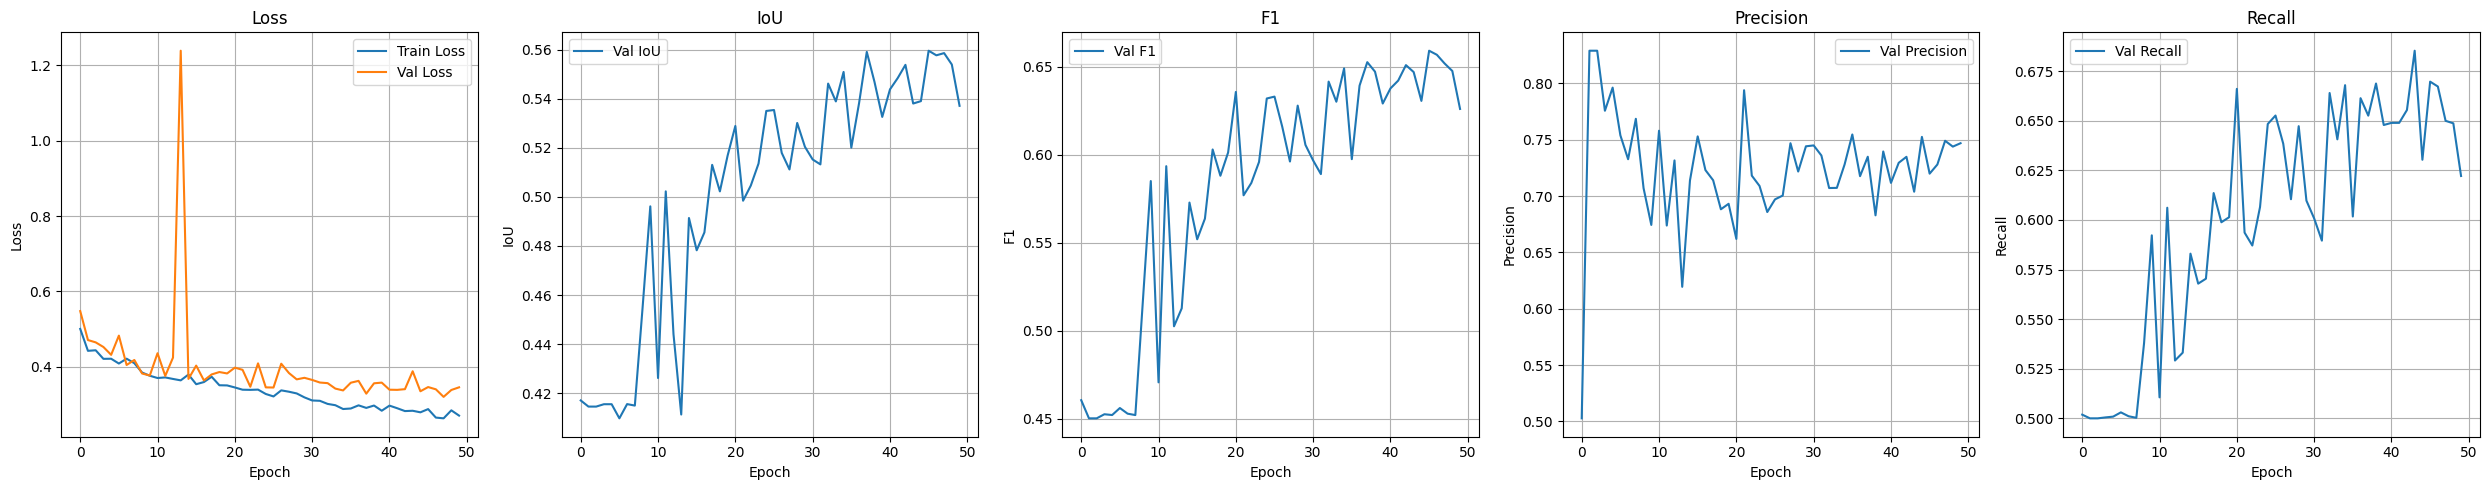


=== Performance Metrics Summary ===
IoU     - Best: 0.5596 | Final: 0.5371
F1      - Best: 0.6590 | Final: 0.6260
Precision - Best: 0.8291 | Final: 0.7470
Recall  - Best: 0.6853 | Final: 0.6221
Val Loss - Best: 0.3204 | Final: 0.3457



In [ ]:
from geoai.utils import plot_performance_metrics
hist = "/content/drive/MyDrive/masters_final_folder/model_all3/training_history.pth"
df = plot_performance_metrics(hist)


## Test Dataset Performance

Let's examine the metrics of our unseen test dataset:

In [ ]:
import geoai
import rasterio
import numpy as np
from pathlib import Path

# Paths wrapped in Path objects
test_images = Path('/content/drive/MyDrive/masters_final_folder/normalised_ongu_training_tiles')
test_masks = Path('/content/drive/MyDrive/masters_final_folder/test_buffered_masks_5Metre')

model_path = '/content/drive/MyDrive/masters_final_folder/model_all3/best_model.pth'
prediction_dir = Path('/content/drive/MyDrive/masters_final_folder/model_all3/predictions')
prediction_dir.mkdir(parents=True, exist_ok=True)

# Confusion matrix counts
TP = 0
FP = 0
FN = 0
TN = 0

# Iterate through test images
for image_path in sorted(test_images.glob("*.tif")):

    # Map image filename (ongu_training__X.tif) to mask filename (ongu_mask_X.tif)
    mask_filename = image_path.name.replace('ongu_training__', 'ongu_mask_')
    mask_path = test_masks / mask_filename
    prediction_path = prediction_dir / image_path.name

    # Check if ground truth mask exists before proceeding
    if not mask_path.exists():
        print(f"Warning: Ground truth mask not found at {mask_path}. Skipping evaluation for this image.")
        continue

    # Generate prediction
    geoai.semantic_segmentation(
        input_path=str(image_path),
        output_path=str(prediction_path),
        model_path=model_path,
        architecture="unet",
        encoder_name="resnet34",
        num_channels=3,
        num_classes=2,
        window_size=128,
        overlap=0,
        batch_size=4,
    )

    # Read predicted and ground truth masks
    with rasterio.open(prediction_path) as src:
        prediction = src.read(1)

    with rasterio.open(mask_path) as src:
        ground_truth = src.read(1)

    # Convert to binary masks
    prediction = prediction == 1
    ground_truth = ground_truth > 0

    # Calculate confusion matrix components
    TP += np.sum(prediction & ground_truth)
    FP += np.sum(prediction & ~ground_truth)
    FN += np.sum(~prediction & ground_truth)
    TN += np.sum(~prediction & ~ground_truth)

# Calculate metrics
total_samples = TP + FP + FN + TN
if total_samples > 0:
    iou = TP / (TP + FP + FN) if TP + FP + FN else 0
    precision = TP / (TP + FP) if TP + FP else 0
    recall = TP / (TP + FN) if TP + FN else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )
    accuracy = (TP + TN) / total_samples

    print("\nTest Dataset Results")
    print("--------------------")
    print(f"IoU:       {iou:.4f}")
    print(f"F1 Score:  {f1:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"Accuracy:  {accuracy:.4f}")
else:
    print("No valid predictions compared with ground truth masks.")

Input file format: GeoTIFF (.tif)
Processing 1 windows...


4it [00:00, 10.29it/s]


Predicted classes: 1 classes, Background: 100.0%
Inference completed in 0.39 seconds
Saved prediction to /content/drive/MyDrive/masters_final_folder/model_all3/predictions/ongu_training__0.tif
Input file format: GeoTIFF (.tif)
Processing 1 windows...


4it [00:00, 10.23it/s]


Predicted classes: 1 classes, Background: 100.0%
Inference completed in 0.40 seconds
Saved prediction to /content/drive/MyDrive/masters_final_folder/model_all3/predictions/ongu_training__1.tif
Input file format: GeoTIFF (.tif)
Processing 1 windows...


4it [00:03,  1.04it/s]


... (529 outputs left out)

4it [00:00,  9.73it/s]


Predicted classes: 1 classes, Background: 100.0%
Inference completed in 0.42 seconds
Saved prediction to /content/drive/MyDrive/masters_final_folder/model_all3/predictions/ongu_training__98.tif
Input file format: GeoTIFF (.tif)
Processing 1 windows...


4it [00:00,  9.64it/s]

Predicted classes: 2 classes, Background: 97.4%
Inference completed in 0.42 seconds
Saved prediction to /content/drive/MyDrive/masters_final_folder/model_all3/predictions/ongu_training__99.tif

Test Dataset Results
--------------------
IoU:       0.2005
F1 Score:  0.3340
Precision: 0.3240
Recall:    0.3445
Accuracy:  0.8142


## Performance Metrics

**IoU (Intersection over Union)** and **Dice score** are both popular metrics used to evaluate the similarity between two binary masks—often in image segmentation tasks. While they are related, they are not the same.

---

### 🔸 **Definitions**

#### **IoU (Jaccard Index)**

$$
\text{IoU} = \frac{|A \cap B|}{|A \cup B|}
$$

* Measures the overlap between predicted region $A$ and ground truth region $B$ relative to their union.
* Ranges from 0 (no overlap) to 1 (perfect overlap).

#### **Dice Score (F1 Score for Sets)**

$$
\text{Dice} = \frac{2|A \cap B|}{|A| + |B|}
$$

* Measures the overlap between $A$ and $B$, but gives more weight to the intersection.
* Also ranges from 0 to 1.

---

### 🔸 **Key Differences**

| Metric   | Formula                     | Penalizes                      | Sensitivity                      |
| -------- | --------------------------- | ------------------------------ | -------------------------------- |
| **IoU**  | $\frac{TP}{TP + FP + FN}$   | FP and FN equally              | Less sensitive to small objects  |
| **Dice** | $\frac{2TP}{2TP + FP + FN}$ | Less harsh on small mismatches | More sensitive to small overlaps |

> TP: True Positive, FP: False Positive, FN: False Negative

---

### 🔸 **Relationship**

Dice and IoU are mathematically related:

$$
\text{Dice} = \frac{2 \cdot \text{IoU}}{1 + \text{IoU}} \quad \text{or} \quad \text{IoU} = \frac{\text{Dice}}{2 - \text{Dice}}
$$

---

### 🔸 **When to Use What**

* **IoU**: Common in object detection and semantic segmentation benchmarks (e.g., COCO, Pascal VOC).
* **Dice**: Preferred in medical imaging and when class imbalance is an issue, due to its sensitivity to small regions.